# CLIP retriever

The goal of this project is to use CLIP to build text to image and image to text retrieval.

Specifically, we are asked to 
1. Retrieve movie posters based on genre (Text -> Image)
1. Classify the genre of a poster (Image -> Text)
1. Retrieve the poster based on the movie title (Text -> Image)
1. Retrieve the movie title based on the poster (Image -> Text)

## Data Preperation

Let us first load the dataset (saved in the folder posters)

In [1]:
import pandas as pd
import os
from PIL import Image

In [2]:
csv_path = "posters/MovieGenre.csv"
image_dir = "posters/SampleMoviePosters/SampleMoviePosters/"

df = pd.read_csv(csv_path, encoding='latin-1')
print(f"A total of {len(df)} entries.")

df = df.dropna(subset=['imdbId', 'Title', 'Genre'])
print(f"After droping NA we have a total of {len(df)} entries.")

A total of 40108 entries.
After droping NA we have a total of 39963 entries.


In [6]:
df = df.drop_duplicates(subset=['imdbId'])
print(f"After removing duplicate imdbIds we have a total of {len(df)} entries.")

After removing duplicate imdbIds we have a total of 39370 entries.


In [8]:
images = []
titles = []
movie_genres = []

for index, row in df.iterrows():
    # In the standard IMDB poster dataset, images are named "{imdbId}.jpg"
    imdb_id = row['imdbId'] 
    img_path = os.path.join(image_dir, f"{imdb_id}.jpg")
    
    if os.path.exists(img_path):
        try:
            img = Image.open(img_path)
            images.append(img)
            
            titles.append(row['Title'])
            
            # Split the "Action|Adventure|Sci-Fi" string into a list
            g_list = [g.strip() for g in row['Genre'].split('|')]
            movie_genres.append(g_list)
            
                
        except Exception as e:
            print(f"Skipping corrupted/unreadable image {img_path}: {e}")
    else:
        print(f"Image {img_path} does not exist.")

Image posters/SampleMoviePosters/SampleMoviePosters/114709.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113497.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113228.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114885.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113041.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113277.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114319.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112302.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/114576.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/113189.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112346.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/112896.jpg does not exist.
Image posters/SampleMoviePosters/SampleMoviePosters/

In [9]:
print(f"Successfully loaded {len(images)} posters")

Successfully loaded 997 posters


In [10]:
print(f"Length of titles is {len(titles)}")
print(f"Length of genres is {len(movie_genres)}")

Length of titles is 997
Length of genres is 997


In [34]:
# Flatten the list of lists and then convert to a set
unique_genres = set([genre for sublist in movie_genres for genre in sublist])
unique_genres = list(unique_genres)
print(f"A total of {len(unique_genres)} genres.")
print(unique_genres)

A total of 23 genres.
['Mystery', 'Documentary', 'Sci-Fi', 'Action', 'Fantasy', 'Biography', 'Short', 'Comedy', 'Animation', 'Family', 'Horror', 'Romance', 'Music', 'Adventure', 'Film-Noir', 'War', 'Sport', 'Thriller', 'Musical', 'Western', 'History', 'Crime', 'Drama']


## Retrieval

Let us now use the CLIP model for retrieval

In [15]:
import torch
import clip


In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

100%|███████████████████████████████████████| 338M/338M [01:53<00:00, 3.11MiB/s]
/home/beauty/Multimodal-CLIP/.venv/lib/python3.14/site-packages/torch/jit/_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


In [18]:
# Precompute Image Features (Run once to save time)
image_inputs = torch.stack([preprocess(img) for img in images]).to(device)
with torch.no_grad():
    image_features = model.encode_image(image_inputs)
    image_features /= image_features.norm(dim=-1, keepdim=True)

In [19]:
def get_text_features(text_list):
    text_inputs = clip.tokenize(text_list).to(device)
    with torch.no_grad():
        text_features = model.encode_text(text_inputs)
        text_features /= text_features.norm(dim=-1, keepdim=True)
    return text_features

In [25]:
def retrieve_posters_by_genre(target_genre, top_k=3, prompt=None):
    if prompt is None:
        prompt = f"A movie poster for a {target_genre} movie."

    text_features = get_text_features([prompt])
    
    similarities = (text_features @ image_features.T).squeeze(0)
    top_indices = similarities.topk(top_k).indices.tolist()
    
    return [images[i] for i in top_indices]

In [35]:
def classify_poster_genre(image_idx, top_k=3, prompt_template="A movie poster for a {} movie."):

    prompts = [prompt_template.format(g) for g in unique_genres]
    text_features = get_text_features(prompts).float()
        
    target_image_feature = image_features[image_idx].unsqueeze(0).float()
    
    text_probs = (100.0 * target_image_feature @ text_features.T).softmax(dim=-1)
    
    top_probs, top_indices = text_probs.cpu().topk(top_k, dim=-1)
    
    top_probs = top_probs.squeeze(0).tolist()
    top_indices = top_indices.squeeze(0).tolist()
    
    results = []
    
    for prob, idx in zip(top_probs, top_indices):
        genre = unique_genres[idx]
        results.append((genre, prob))
        
    return results

In [48]:
def retrieve_poster_by_title(target_title, top_k=3, prompt_template="A movie poster for the film {}."):
    prompt = prompt_template.format(target_title)
    text_features = get_text_features([prompt])
    
    probs = (100.0 * text_features.float() @ image_features.float().T).softmax(dim=-1).squeeze(0)
    top_probs, top_indices = probs.cpu().topk(top_k, dim=-1)

    top_probs = top_probs.tolist()
    top_indices = top_indices.tolist()

    results = []

    for (prob, i) in zip(top_probs, top_indices):
        retrieved_title = titles[i]
        retrieved_image = images[i]
        results.append((retrieved_image, prob, retrieved_title))

    
    return results

In [24]:
def retrieve_title_by_poster(image_idx, prompt_template="A movie poster for the film {}.", top_k=3):

    target_image_feature = image_features[image_idx].unsqueeze(0).float()

    prompts = [prompt_template.format(t) for t in titles] 
    text_features = get_text_features(prompts).float()
    
    text_probs = (100.0 * target_image_feature @ text_features.T).softmax(dim=-1)
    top_probs, top_indices = text_probs.cpu().topk(top_k, dim=-1)
    top_probs = top_probs.squeeze(0).tolist()
    top_indices = top_indices.squeeze(0).tolist()
    
    results = []
    for rank, (prob, idx) in enumerate(zip(top_probs, top_indices), 1):
        predicted_title = titles[idx]
        results.append((predicted_title, prob))
        
    return results

Let us now test the code

In [38]:
import matplotlib.pyplot as plt
import numpy as np

In [29]:
posters = retrieve_posters_by_genre("Horror")

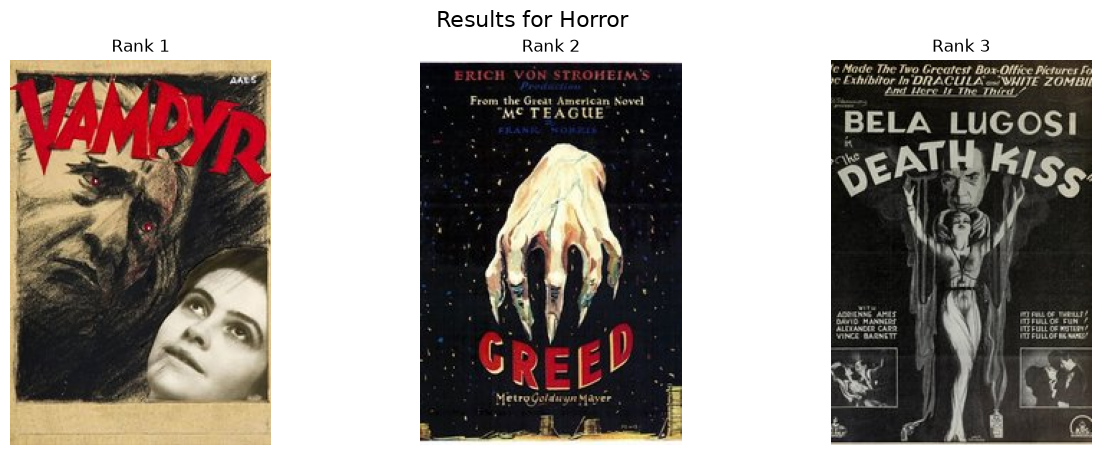

In [30]:
fig, axes = plt.subplots(1,3,figsize=(15,5))
for i, img in enumerate(posters):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Rank {i+1}")
plt.suptitle("Results for Horror", fontsize=16)
plt.show()

In [40]:
predicted_genres = classify_poster_genre(3)

In [42]:
predicted_genres

[('Musical', 0.43407541513442993),
 ('Animation', 0.10896863043308258),
 ('Biography', 0.09291169792413712)]

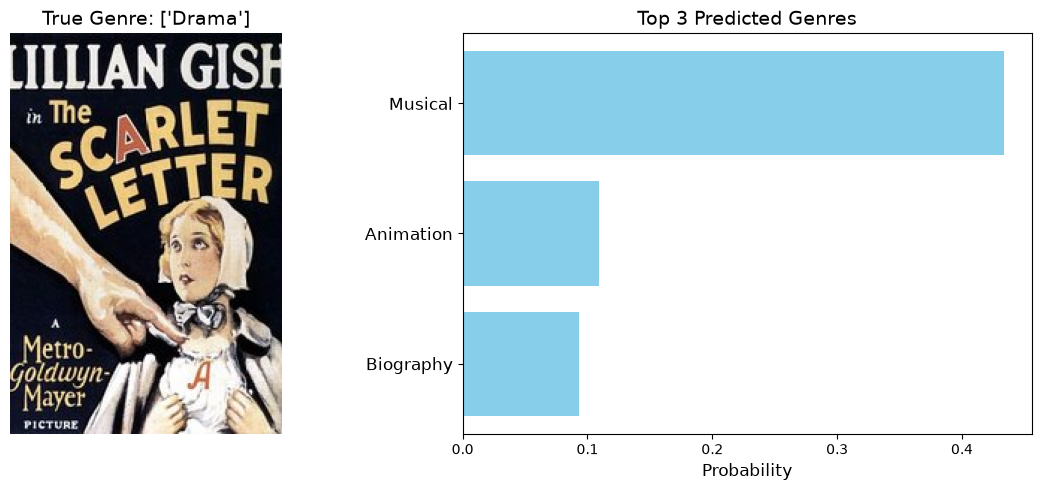

In [45]:
img = images[3]
true_genre = movie_genres[3]

pred_genres = [pred[0] for pred in predicted_genres]
pred_probs = [pred[1] for pred in predicted_genres]

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title(f"True Genre: {true_genre}", fontsize=14)
plt.axis("off")

plt.subplot(1,2,2)
y = np.arange(len(predicted_genres))
plt.barh(y, pred_probs, color="skyblue")

# Invert y-axis so the #1 highest probability is at the very top of the chart
plt.gca().invert_yaxis()

plt.yticks(y, pred_genres, fontsize=12)
plt.xlabel("Probability", fontsize=12)
plt.title("Top 3 Predicted Genres", fontsize=14)

plt.tight_layout()
plt.show()


In [49]:
predicted_posters = retrieve_poster_by_title("Matrix")

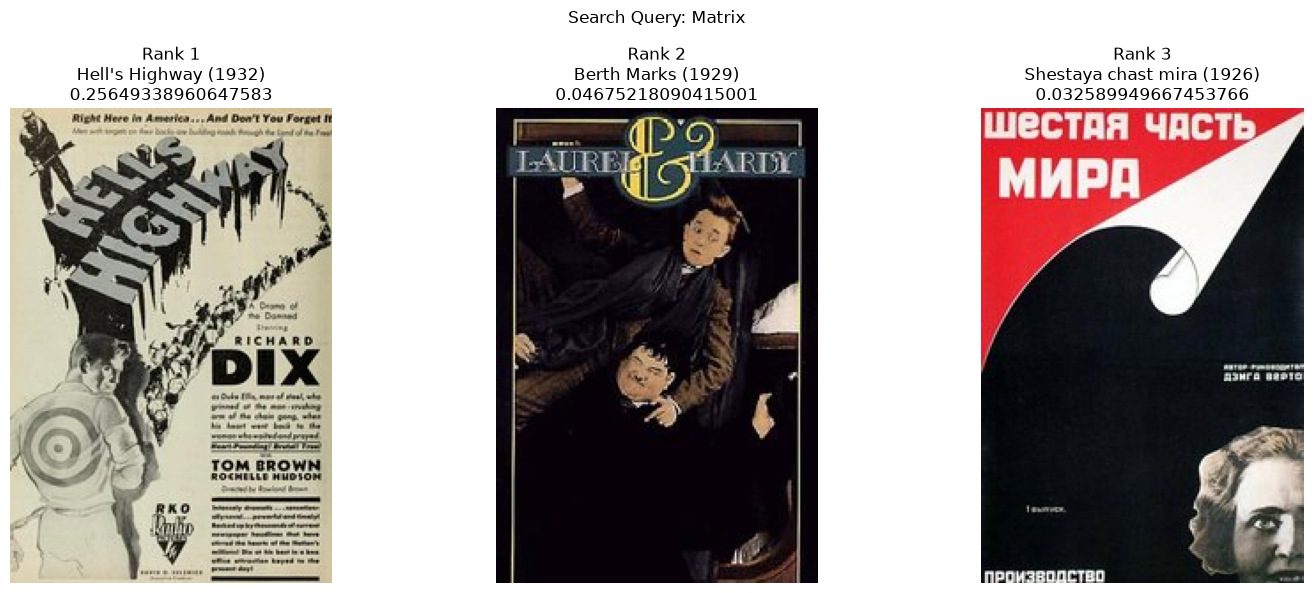

In [52]:
fig, axes = plt.subplots(1, len(predicted_posters), figsize=(15,6))
for i, (img,prob,title) in enumerate(predicted_posters):
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(f"Rank {i+1}\n{title}\n{prob}", fontsize=12)
plt.suptitle("Search Query: Matrix")
plt.tight_layout()
plt.show()

Hm... it doesn't look too good. Let's try to search with a query that actually exists in the dataset

In [ ]:
predicted_posters = retrieve_poster_by_title("Today we live")

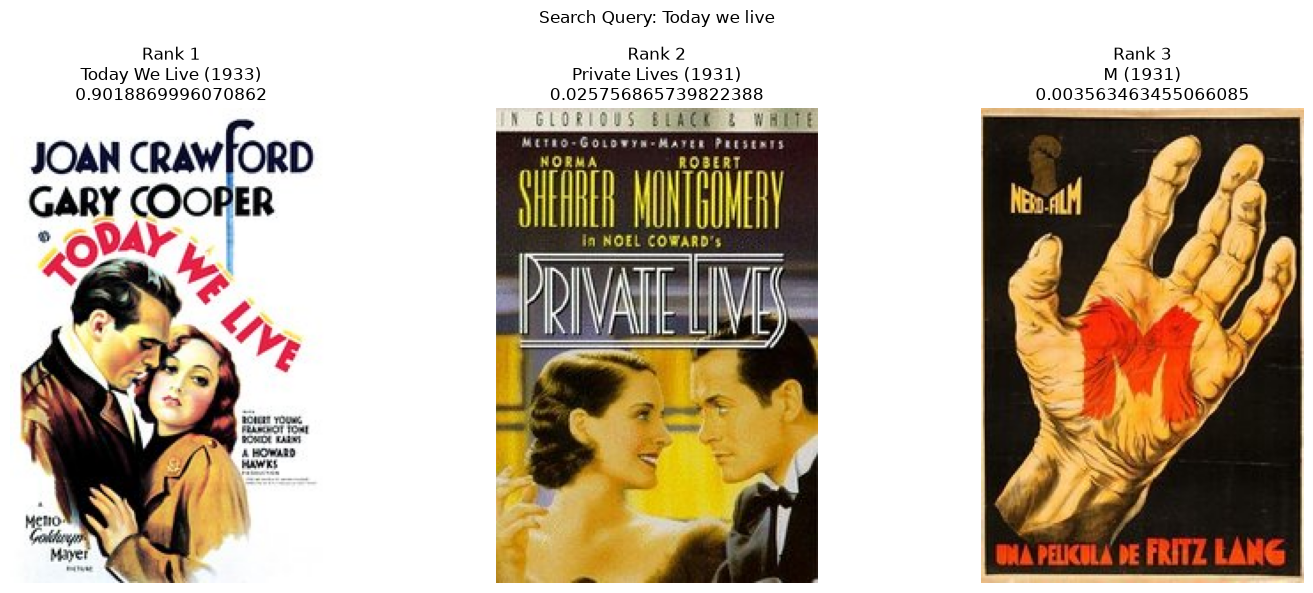

In [54]:
fig, axes = plt.subplots(1, len(predicted_posters), figsize=(15,6))
for i, (img,prob,title) in enumerate(predicted_posters):
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(f"Rank {i+1}\n{title}\n{prob}", fontsize=12)
plt.suptitle("Search Query: Today we live")
plt.tight_layout()
plt.show()

Much better! We see that the model is actually almost certain about the correct poster.

In [55]:
predicted_titles = retrieve_title_by_poster(3)

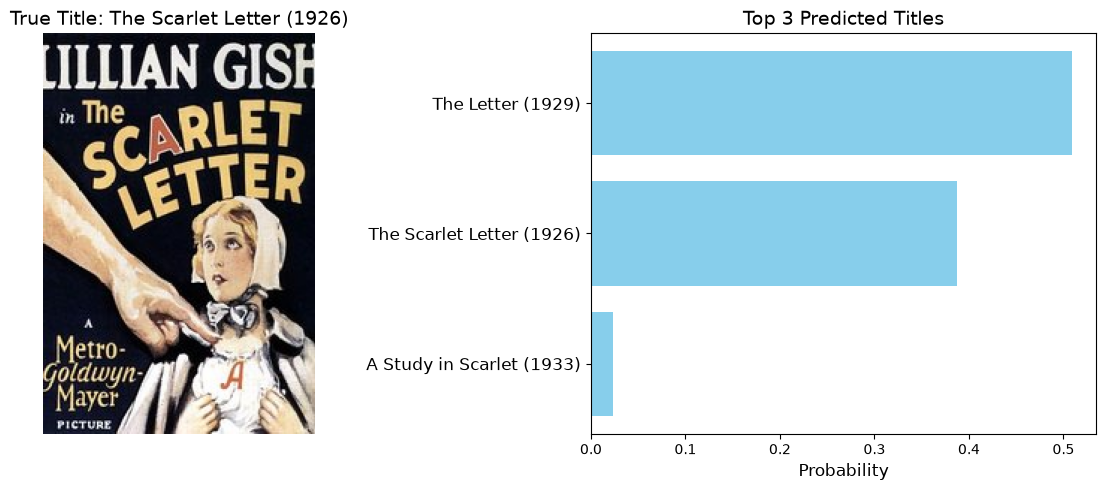

In [57]:
img = images[3]
true_title = titles[3]

pred_titles = [pred[0] for pred in predicted_titles]
pred_probs = [pred[1] for pred in predicted_titles]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title(f"True Title: {true_title}", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
y = np.arange(len(pred_titles))

plt.barh(y, pred_probs, color='skyblue')

# Invert y-axis so the #1 highest probability is at the top
plt.gca().invert_yaxis()

plt.yticks(y, pred_titles, fontsize=12)
plt.xlabel("Probability", fontsize=12)
plt.title("Top 3 Predicted Titles", fontsize=14)

plt.tight_layout()
plt.show()

We see that the model actually misclassifies the movie "The Scarlet Letter (1926)" for the movie "The Letter (1929)".